In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor  
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.model_selection import train_test_split
from scipy.special import expit,softmax # expit : 이진 분류함수 softmax : 다중분류


In [2]:
# logisticRegression() 알고리즘으로 구현하시오 

In [3]:
df = pd.read_csv('data/iris.csv', index_col='caseno')
df.head(5)
df["Species"].unique()

<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

In [4]:
# 붓꽃품종분류 : 89.23% 확률로 Iris-sentosa 품종으로 판별됩니다. 

In [5]:
data = df[['SepalLength',	'SepalWidth',	'PetalLength', 'PetalWidth']].values
label = df['Species'].values
label

<StringArray>
[   'Iris-setosa',    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',
    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',
    'Iris-setosa',    'Iris-setosa',
 ...
 'Iris-virginica', 'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
 'Iris-virginica', 'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
 'Iris-virginica', 'Iris-virginica']
Length: 150, dtype: str

In [6]:
train_data, test_data, train_label, test_label = train_test_split(data,label,random_state=42)

In [7]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [8]:
lr = LogisticRegression(C=20,max_iter=1000)
lr.fit(train_scaled,train_label)
print()

In [9]:
lr.classes_ 

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [10]:
predict = lr.predict(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
test_scaled[:5]

array([[ 0.33066442, -0.54569687,  0.51668341, -0.01795576],
       [-0.15985763,  1.76938075, -1.22111065, -1.22458253],
       [ 2.29275265, -1.00871239,  1.79106573,  1.4568103 ],
       [ 0.20803391, -0.3141891 ,  0.40083048,  0.38425317],
       [ 1.18907802, -0.54569687,  0.57460988,  0.25018353]])

In [11]:
soft1 = softmax(decisions,axis=1)
np.round(soft1,decimals=3)

array([[0.   , 0.99 , 0.01 ],
       [0.995, 0.005, 0.   ],
       [0.   , 0.   , 1.   ],
       [0.   , 0.956, 0.044],
       [0.   , 0.959, 0.041]])

In [12]:
print('train 정확도:', lr.score(train_scaled,train_label))
print('tes 정확도:', lr.score(test_scaled,test_label))

train 정확도: 0.9821428571428571
tes 정확도: 1.0


In [13]:
df

,SepalLength,SepalWidth,PetalLength,PetalWidth,Species
caseno,,,,,
1,5.1,3.5,1.4,0.2,Iris-setosa
2,4.9,3.0,1.4,0.2,Iris-setosa
3,4.7,3.2,1.3,0.2,Iris-setosa
4,4.6,3.1,1.5,0.2,Iris-setosa
5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
146,6.7,3.0,5.2,2.3,Iris-virginica
147,6.3,2.5,5.0,1.9,Iris-virginica
148,6.5,3.0,5.2,2.0,Iris-virginica


In [14]:
train_data[:5]

array([[5. , 3.6, 1.4, 0.2],
       [5.2, 4.1, 1.5, 0.1],
       [5.8, 2.7, 5.1, 1.9],
       [6. , 3.4, 4.5, 1.6],
       [6.7, 3.1, 4.7, 1.5]])

In [ ]:
ss = StandardScaler()
ss.fit(train_data,train_label)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)  

In [16]:
# 붓꽃품종분류 : 89.23% 확률로 Iris-sentosa 품종으로 판별됩니다. 
# 5.1	3.5	1.4	0.2 Iris-setosa
# 4.9	3	1.4	0.2 Iris-setosa
# 4.6	3.1	1.5	0.2 Iris-setosa
# 7	3.2	4.7	1.4  Iris-versicolor
# 6.4	3.2	4.5	1.5 Iris-versicolor
# 5.5	2.3	4	1.3 Iris-versicolor
# 6.3	3.3	6	2.5
# 5.8	2.7	5.1	1.9
# 7.1	3	5.9	2.1


in_data = input('붓꽃품종의 길이, 넓이를 입력하세요. >> 예) 5.1	3.5	1.4	0.2	')
# in_data = '5.1, 3.5, 1.4, 0.2'
# in_data = '4.9,	 3,	 1.4, 0.2'
# in_data = '4.6,	3.1, 1.5, 0.2'
# in_data = '7,	3.2, 4.7, 1.4'
# in_data = '6.4,	3.2, 4.5, 1.5'
# in_data = '5.5,	2.3, 4,	1.3'
# in_data = '6.3,	3.3, 6,	2.5'
# in_data = '5.8,	2.7, 5.1, 1.9'
# in_data = '7.1,	3,	5.9,2.1'

in_data = in_data.split(',') 
in_data = list(map(float, in_data))
in_data

# in_data = in_data.split('\t') 
# in_data = list(map(float, in_data))
# in_data



[5.0, 3.6, 1.4, 0.2]

In [17]:
in_data_scaled = ss.transform([in_data])
proba = lr.predict_proba(in_data_scaled)

result = lr.predict(in_data_scaled)
result2 = lr.predict_proba(in_data_scaled)
print(lr.predict_proba(in_data_scaled))

if result[0] == "Iris-setosa":
    result3 = result2[0][0]
elif result[0] == "Iris-versicolor":
    result3 = result2[0][1]
else: 
    result3 = result2[0][2]
print(result3)
print(f' 붓꽃품종분류 : , ({result3*100:.2f}% 확률로 {result} 판별합니다.)')


[[9.99499946e-01 5.00054289e-04 8.31259924e-17]]
0.9994999457107809
 붓꽃품종분류 : , (99.95% 확률로 ['Iris-setosa'] 판별합니다.)


In [20]:
new_scaled = ss.transform ([[5.1,3.5,1.4,0.2]])
new2_scaled = ss.transform ([[7,3.2,4.7,1.4]])
new3_scaled = ss.transform ([[6.3,3.3,6,2.5]])

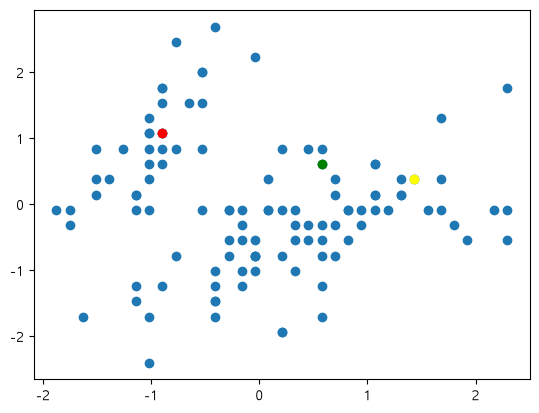

In [21]:
plt.scatter(train_scaled[:, 0], train_scaled[:, 1])

plt.plot(new_scaled[:, 0], new_scaled[:, 1], 'o-', color='red')
plt.plot(new2_scaled[:, 0], new2_scaled[:, 1], 'o-', color='yellow')
plt.plot(new3_scaled[:, 0], new3_scaled[:, 1], 'o-', color='green')

plt.show()